# Task-1

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score,silhouette_score
from sklearn.datasets import make_moons, make_circles

In [2]:
# 1. Load the dataset
df = pd.read_csv("customer_rfm.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

First 5 rows:
  customer_id  recency_days  frequency  monetary
0   CUST00001           342          4   7861.13
1   CUST00002           644          1   3703.22
2   CUST00003           604          2   4582.42
3   CUST00004           424          1    200.00
4   CUST00005           156          8  25822.11

Dataset Shape:
(1500, 4)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   1500 non-null   str    
 1   recency_days  1500 non-null   int64  
 2   frequency     1500 non-null   int64  
 3   monetary      1500 non-null   float64
dtypes: float64(1), int64(2), str(1)
memory usage: 60.2 KB


In [3]:
# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
customer_id     0
recency_days    0
frequency       0
monetary        0
dtype: int64


In [4]:
# 3. Check the range of each feature
features = ["recency_days", "frequency", "monetary"]

print("\nFeature Ranges:")
print(df[features].agg(["min", "max"]))

# Prepare the feature data.
# customer_id is excluded because it is an identifier,
# not a customer purchasing behavior feature.

X = df[features].to_numpy(dtype=float)


Feature Ranges:
     recency_days  frequency   monetary
min             1          1     200.00
max           729         29  103858.45


In [5]:
# 4. Implement K-Means from Scratch

def kmeans_scratch(X, k, seed=42, max_iters=300):

    # Convert input into a NumPy array
    X = np.asarray(X, dtype=float)

    # Validate the input
    if X.ndim != 2:
        raise ValueError("X must be a 2-dimensional array.")

    if not np.isfinite(X).all():
        raise ValueError("X must not contain missing or infinite values.")

    n_samples = X.shape[0]

    if not 1 <= k <= n_samples:
        raise ValueError("k must be between 1 and the number of samples.")

    if max_iters < 1:
        raise ValueError("max_iters must be at least 1.")

    # Create a random number generator
    rng = np.random.default_rng(seed)

    # Step 1: Initialize centroids using random data points
    initial_indices = rng.choice(n_samples, size=k, replace=False)
    centroids = X[initial_indices].copy()

    # Store the number of iterations
    n_iterations = 0

    # Repeat the Assign and Update steps
    for iteration in range(1, max_iters + 1):

        # Step 2: ASSIGN each point to its nearest centroid
        distances = np.linalg.norm(
            X[:, None, :] - centroids[None, :, :],
            axis=2
        )

        labels = distances.argmin(axis=1)

        # Step 3: UPDATE centroids using the mean of each cluster
        new_centroids = centroids.copy()

        for cluster in range(k):

            # Select all data points belonging to this cluster
            cluster_points = X[labels == cluster]

            if len(cluster_points) > 0:

                # Move the centroid to the cluster's mean
                new_centroids[cluster] = cluster_points.mean(axis=0)

            # If a cluster is empty, keep its previous centroid.
            # This prevents errors when calculating the mean.

        n_iterations = iteration

        # Step 4: Check whether the centroids have stopped moving
        if np.allclose(centroids, new_centroids, rtol=1e-5, atol=1e-8):
            centroids = new_centroids
            break

        centroids = new_centroids

    # Assign points again using the final centroids
    distances = np.linalg.norm(
        X[:, None, :] - centroids[None, :, :],
        axis=2
    )

    labels = distances.argmin(axis=1)

    return labels, centroids, n_iterations

In [6]:
# 5. Test the Scratch Implementation
k = 5

labels, centroids, iterations = kmeans_scratch(
    X=X,
    k=k,
    seed=42,
    max_iters=300
)

print("\nK-Means from Scratch Results")
print("--------------------------------")

print("Number of clusters:", k)
print("Number of iterations:", iterations)
print("Centroids shape:", centroids.shape)

print("\nFinal Centroids:")
print(pd.DataFrame(centroids, columns=features))


K-Means from Scratch Results
--------------------------------
Number of clusters: 5
Number of iterations: 30
Centroids shape: (5, 3)

Final Centroids:
   recency_days  frequency      monetary
0     61.031746  10.611111  30036.856389
1    448.976789   2.810445   4831.554333
2    123.130337   7.750562  18772.005461
3     55.277778   7.518519  74793.580648
4     31.500000  13.966292  50609.210225


In [7]:
# 6. Check the Cluster Assignments
df["cluster"] = labels

print("\nNumber of Customers in Each Cluster:")
print(df["cluster"].value_counts().sort_index())

print("\nFirst 10 Customer Assignments:")
print(df[["customer_id", "recency_days", "frequency",
          "monetary", "cluster"]].head(10))


Number of Customers in Each Cluster:
cluster
0    252
1    517
2    445
3    108
4    178
Name: count, dtype: int64

First 10 Customer Assignments:
  customer_id  recency_days  frequency  monetary  cluster
0   CUST00001           342          4   7861.13        1
1   CUST00002           644          1   3703.22        1
2   CUST00003           604          2   4582.42        1
3   CUST00004           424          1    200.00        1
4   CUST00005           156          8  25822.11        0
5   CUST00006           508          1   5524.93        1
6   CUST00007            69          9  28448.80        0
7   CUST00008            20         11  26444.16        0
8   CUST00009           274          2   1920.85        1
9   CUST00010            10         11  31508.46        0


# Task-2

In [8]:
# 1. Scale the three features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

print("Scaled Data Shape:", X_scaled.shape)

Scaled Data Shape: (1500, 3)


In [9]:
# 2. Use the same initial centroids for both models
k = 5
seed = 42
max_iters = 300

rng = np.random.default_rng(seed)
initial_indices = rng.choice(len(X_scaled), size=k, replace=False)
initial_centroids = X_scaled[initial_indices].copy()

In [10]:
# 3. Run our Scratch K-Means implementation

scratch_labels, scratch_centroids, scratch_iterations = kmeans_scratch(
    X_scaled,
    k=k,
    seed=seed,
    max_iters=max_iters
)

In [11]:
# 4. Run Scikit-learn K-Means

sklearn_model = KMeans(
    n_clusters=k,
    init=initial_centroids,
    n_init=1,
    max_iter=max_iters,
    random_state=seed,
    algorithm="lloyd"
)

sklearn_labels = sklearn_model.fit_predict(X_scaled)

In [12]:
# 5. Compare Both Implementations using ARI

ari_score = adjusted_rand_score(
    scratch_labels,
    sklearn_labels
)

print("\nTask 2 Results")
print("-" * 40)

print("Number of clusters:", k)
print("Scratch iterations:", scratch_iterations)
print("Scikit-learn iterations:", sklearn_model.n_iter_)
print("Adjusted Rand Index (ARI):", round(ari_score, 4))

if ari_score == 1.0:
    print("\nResult: Both implementations produce identical groupings.")
else:
    print("\nResult: The groupings differ.")
    print("Check convergence and empty-cluster handling.")


Task 2 Results
----------------------------------------
Number of clusters: 5
Scratch iterations: 18
Scikit-learn iterations: 17
Adjusted Rand Index (ARI): 1.0

Result: Both implementations produce identical groupings.


In [13]:
# 6. Display the Cluster Sizes
comparison = pd.DataFrame({
    "Scratch K-Means": pd.Series(scratch_labels).value_counts().sort_index(),
    "Scikit-learn K-Means": pd.Series(sklearn_labels).value_counts().sort_index()
}).fillna(0).astype(int)

print("\nCluster Sizes:")
print(comparison)


Cluster Sizes:
   Scratch K-Means  Scikit-learn K-Means
0              514                   514
1              340                   340
2              305                   305
3              211                   211
4              130                   130


- The three customer features were scaled using StandardScaler before applying K-Means with five clusters. I compared my from-scratch implementation with scikit-learn's implementation using the Adjusted Rand Index (ARI).

- ARI is appropriate because cluster numbers are arbitrary. Two implementations can produce identical customer groupings while assigning different numbers to the clusters. Using the same initial centroids makes the comparison fairer by reducing differences caused by random initialization.

# Task-3

In [14]:
# 1. Prepare the customer features

X_unscaled = df[features].to_numpy(dtype=float)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_unscaled)

print("Original Data Shape:", X_unscaled.shape)
print("Scaled Data Shape:", X_scaled.shape)

Original Data Shape: (1500, 3)
Scaled Data Shape: (1500, 3)


In [15]:
# 2. Run K-Means on Unscaled Data

kmeans_unscaled = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

unscaled_labels = kmeans_unscaled.fit_predict(X_unscaled)

In [16]:
# 3. Run K-Means on Scaled Data

kmeans_scaled = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

scaled_labels = kmeans_scaled.fit_predict(X_scaled)

In [17]:
# 4. Compare the Clusterings using ARI

ari_score = adjusted_rand_score(
    unscaled_labels,
    scaled_labels
)

print("\n--- Scaled vs Unscaled Comparison ---")
print("Number of clusters:", 5)
print("Adjusted Rand Index:", round(ari_score, 4))


--- Scaled vs Unscaled Comparison ---
Number of clusters: 5
Adjusted Rand Index: 0.3805


In [18]:
# 5. Display Feature Ranges in Unscaled Data

df_unscaled = df[features].copy()
df_unscaled["cluster"] = unscaled_labels

unscaled_ranges = df_unscaled.groupby("cluster")[features].agg(
    ["min", "max"]
)

print("\n--- Feature Ranges Within Each Unscaled Cluster ---")
print(unscaled_ranges.round(2))


--- Feature Ranges Within Each Unscaled Cluster ---
        recency_days      frequency      monetary           
                 min  max       min max       min        max
cluster                                                     
0                  1  107         1  28  40443.11   62538.72
1                 13  729         1  15    200.00   11555.20
2                  2  109         1  25  63350.09  103858.45
3                  1  299         1  28  24298.26   39894.99
4                  4  299         1  29  11749.45   24271.12


In [19]:
# 6. Compare Overall Feature Ranges

print("\n--- Overall Feature Ranges ---")
print(X_unscaled.min(axis=0))
print(X_unscaled.max(axis=0))

print("\n--- Overall Feature Standard Deviations ---")
print(df[features].std().round(2))


--- Overall Feature Ranges ---
[  1.   1. 200.]
[7.2900000e+02 2.9000000e+01 1.0385845e+05]

--- Overall Feature Standard Deviations ---
recency_days      213.46
frequency           5.93
monetary        20727.73
dtype: float64


In [20]:
# 7. Compare Cluster Sizes

cluster_sizes = pd.DataFrame({
    "Unscaled": pd.Series(unscaled_labels).value_counts().sort_index(),
    "Scaled": pd.Series(scaled_labels).value_counts().sort_index()
}).fillna(0).astype(int)

print("\n--- Cluster Sizes ---")
print(cluster_sizes)


--- Cluster Sizes ---
   Unscaled  Scaled
0       178     130
1       516     324
2       108     356
3       257     207
4       441     483


In [21]:
# 8. Summarize the Unscaled Clusters

print("\n--- Unscaled Cluster Profiles ---")

unscaled_profiles = df[features].assign(
    cluster=unscaled_labels
).groupby("cluster")[features].mean()

print(unscaled_profiles.round(2))


--- Unscaled Cluster Profiles ---
         recency_days  frequency  monetary
cluster                                   
0               31.50      13.97  50609.21
1              449.73       2.81   4818.15
2               55.28       7.52  74793.58
3               61.56      10.60  29925.77
4              123.39       7.72  18693.10


### Conclusion: Scaled vs Unscaled K-Means

The ARI between the scaled and unscaled clusterings was **0.3805**. This indicates that scaling substantially changed the customer groupings, and the two approaches produced different segmentation results.

K-Means calculates distances between data points and centroids. When features have different numerical scales, features with larger numerical differences can dominate these distances. StandardScaler puts the features on comparable scales, allowing `recency_days`, `frequency`, and `monetary` to contribute more comparably to the distance calculation.

In my unscaled results, **monetary** had the greatest numerical scale, with values ranging from ₹200.00 to ₹103,858.45 and a standard deviation of ₹20,727.73. In comparison, `frequency` ranged from 1 to 29 purchases, with a standard deviation of 5.93. Therefore, `frequency` had relatively little influence on the unscaled distance calculations, while `recency_days` also had less influence relative to monetary because its numerical scale was much smaller.

In future projects, I would check features such as income, transaction amounts, population, and other large-valued measurements for scale differences before applying distance-based algorithms. I would select an appropriate scaling method based on the data and the business objective.

# Task-4

In [22]:
# 1. Calculate the skewness of each original feature

X_original = df[features].copy()

print("Original Feature Skewness:")
print(X_original.skew().round(4))

Original Feature Skewness:
recency_days    0.9597
frequency       1.1819
monetary        1.2264
dtype: float64


In [23]:
# 2. Scale the original features

scaler_original = StandardScaler()
X_original_scaled = scaler_original.fit_transform(X_original)

In [24]:
# 3. Apply log1p to frequency and monetary

X_transformed = X_original.copy()

X_transformed["frequency"] = np.log1p(X_transformed["frequency"])
X_transformed["monetary"] = np.log1p(X_transformed["monetary"])

print("\nTransformed Feature Skewness:")
print(X_transformed.skew().round(4))

# Scale the transformed features
scaler_transformed = StandardScaler()
X_transformed_scaled = scaler_transformed.fit_transform(X_transformed)


Transformed Feature Skewness:
recency_days    0.9597
frequency      -0.0307
monetary       -0.6749
dtype: float64


In [25]:
# 4. Run K-Means on both versions

k = 5

model_original = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

labels_original = model_original.fit_predict(X_original_scaled)

model_transformed = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

labels_transformed = model_transformed.fit_predict(X_transformed_scaled)

In [26]:
# 5. Compare the clustering results

ari_score = adjusted_rand_score(
    labels_original,
    labels_transformed
)

silhouette_original = silhouette_score(
    X_original_scaled,
    labels_original
)

silhouette_transformed = silhouette_score(
    X_transformed_scaled,
    labels_transformed
)

comparison_results = pd.DataFrame({
    "Version": ["Original Scaled", "Log-Transformed Scaled"],
    "Inertia": [
        model_original.inertia_,
        model_transformed.inertia_
    ],
    "Silhouette Score": [
        silhouette_original,
        silhouette_transformed
    ]
})

print("\nClustering Comparison:")
print(comparison_results.round(4).to_string(index=False))

print("\nARI between the two clusterings:", round(ari_score, 4))


Clustering Comparison:
               Version  Inertia  Silhouette Score
       Original Scaled 669.2140            0.4417
Log-Transformed Scaled 763.2771            0.3621

ARI between the two clusterings: 0.4683


In [27]:
# 6. Profile the original scaled clusters

original_profile_data = X_original.copy()
original_profile_data["cluster"] = labels_original

original_profiles = original_profile_data.groupby("cluster")[features].mean()
original_sizes = original_profile_data["cluster"].value_counts().sort_index()

original_profiles["customer_count"] = original_sizes
original_profiles["percentage"] = (
    original_sizes / len(X_original) * 100
)

In [28]:
# 7. Profile the log-transformed clusters

transformed_profile_data = X_original.copy()
transformed_profile_data["cluster"] = labels_transformed

transformed_profiles = transformed_profile_data.groupby("cluster")[features].mean()
transformed_sizes = transformed_profile_data["cluster"].value_counts().sort_index()

transformed_profiles["customer_count"] = transformed_sizes
transformed_profiles["percentage"] = (
    transformed_sizes / len(X_original) * 100
)

print("\nOriginal Scaled Cluster Profiles:")
print(original_profiles.round(2))

print("\nLog-Transformed Cluster Profiles:")
print(transformed_profiles.round(2))


Original Scaled Cluster Profiles:
         recency_days  frequency  monetary  customer_count  percentage
cluster                                                               
0               65.40       4.01  68078.29             130        8.67
1              562.94       2.09   4142.34             324       21.60
2              249.85       4.10  12527.44             356       23.73
3               20.14      18.93  46920.58             207       13.80
4               61.82       8.90  23068.87             483       32.20

Log-Transformed Cluster Profiles:
         recency_days  frequency  monetary  customer_count  percentage
cluster                                                               
0               71.43       3.48  59955.55             154       10.27
1              599.19       2.02   3938.38             252       16.80
2              125.40       7.11  19717.05             532       35.47
3              342.82       2.41   5391.69             222       14.80
4      

In [29]:
# 8. Display profiles side by side

side_by_side = pd.concat(
    {
        "Original Scaled": original_profiles,
        "Log-Transformed Scaled": transformed_profiles
    },
    axis=1
)

print("\nSide-by-Side Cluster Profiles:")
print(side_by_side.round(2))


Side-by-Side Cluster Profiles:
        Original Scaled                                                \
           recency_days frequency  monetary customer_count percentage   
cluster                                                                 
0                 65.40      4.01  68078.29            130       8.67   
1                562.94      2.09   4142.34            324      21.60   
2                249.85      4.10  12527.44            356      23.73   
3                 20.14     18.93  46920.58            207      13.80   
4                 61.82      8.90  23068.87            483      32.20   

        Log-Transformed Scaled                                                
                  recency_days frequency  monetary customer_count percentage  
cluster                                                                       
0                        71.43      3.48  59955.55            154      10.27  
1                       599.19      2.02   3938.38            252  

### Conclusion: Log Transformation

The original scaled dataset achieved a silhouette score of **0.4417**, while the log-transformed dataset scored **0.3621**. The ARI was **0.4683**, indicating that the transformation changed the customer groupings.

Original skewness:
- `recency_days`: 0.9597
- `frequency`: 1.1819
- `monetary`: 1.2264

After transformation:
- `recency_days`: 0.9597
- `frequency`: -0.0307
- `monetary`: -0.6749

I chose the **original scaled dataset** because it achieved a higher silhouette score and produced well-separated clusters. For example, 207 customers purchased recently, averaging 18.93 purchases and ₹46,920.58 in spending.

Log transformation reduced skewness, but the original scaled data provided better cluster separation. However, business usefulness should also be considered when choosing the final model.

# Task-5

In [30]:
# Use the original features selected in Task 4
features = ["recency_days", "frequency", "monetary"]

X_task5 = df[features].copy()


In [31]:
# Scale the features
scaler_task5 = StandardScaler()
X_scaled_task5 = scaler_task5.fit_transform(X_task5)

In [32]:
# Test K values from 2 to 10
k_values = range(2, 11)
inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled_task5)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled_task5, labels)
    )

In [33]:
# Display the results
results_task5 = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

print("Task 5: Results for K = 2 to 10")
display(results_task5.round(4))

Task 5: Results for K = 2 to 10


,K,Inertia,Silhouette Score
0,2,2233.0572,0.4426
1,3,1447.7007,0.4595
2,4,873.3661,0.5135
3,5,669.2140,0.4417
4,6,564.1963,0.3917
5,7,485.6458,0.3948
6,8,433.3824,0.3852
7,9,393.1342,0.3741
8,10,360.5544,0.3600


In [34]:
# Find the K with the highest silhouette score
best_index = silhouette_values.index(max(silhouette_values))
best_k = list(k_values)[best_index]

print(f"Highest silhouette score: K = {best_k}")
print(f"Silhouette score: {silhouette_values[best_index]:.4f}")

Highest silhouette score: K = 4
Silhouette score: 0.5135


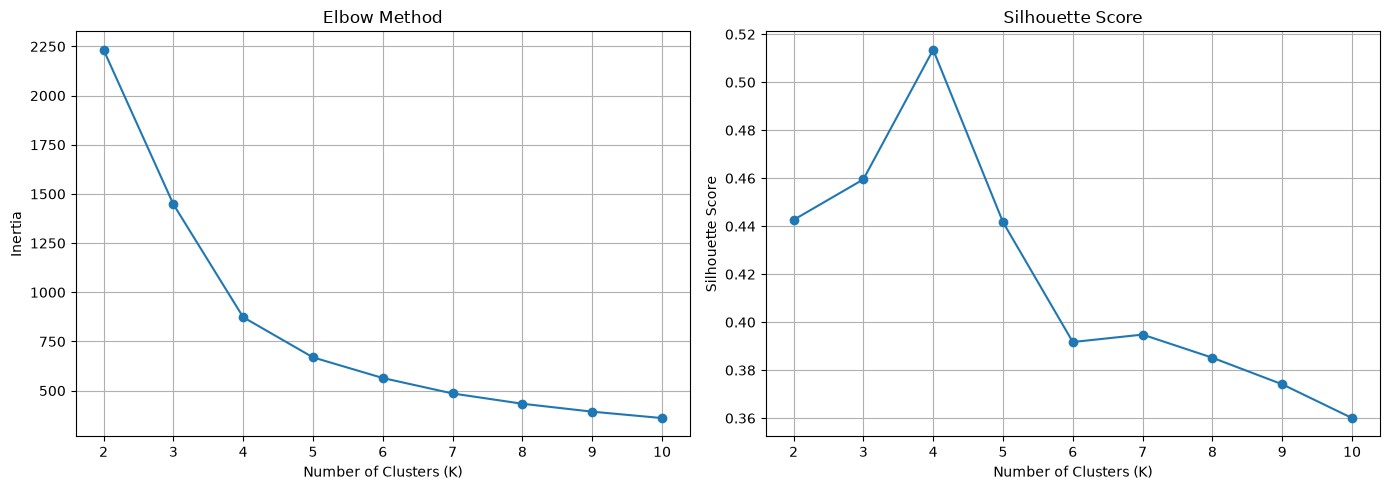

In [35]:
# Plot both methods side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_values), inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(True)

axes[1].plot(list(k_values), silhouette_values, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Task-6

In [36]:
# Get the best K from Task 5
best_k = list(k_values)[silhouette_values.index(max(silhouette_values))]
next_k = best_k + 1

print(f"Silhouette-preferred K: {best_k}")
print(f"Comparing K={best_k} with K={next_k}")

Silhouette-preferred K: 4
Comparing K=4 with K=5


In [37]:
# Fit both models using the original scaled dataset selected in Task 4
model_k = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

model_next = KMeans(
    n_clusters=next_k,
    random_state=42,
    n_init=10
)

labels_k = model_k.fit_predict(X_scaled_task5)
labels_next = model_next.fit_predict(X_scaled_task5)

In [38]:
# Create a function to profile each cluster
def profile_clusters(labels, k):
    profile_df = df[features].copy()
    profile_df["cluster"] = labels

    profile = profile_df.groupby("cluster")[features].mean()
    profile["customer_count"] = profile_df.groupby("cluster").size()
    profile["percentage"] = (
        profile["customer_count"] / len(profile_df) * 100
    )

    print(f"\nCustomer Profiles for K={k}")
    display(profile.round(2))

    return profile

In [39]:
# Show profiles and sizes for both models
profile_k = profile_clusters(labels_k, best_k)
profile_next = profile_clusters(labels_next, next_k)


Customer Profiles for K=4


,recency_days,frequency,monetary,customer_count,percentage
cluster,,,,,
0,492.49,2.14,4357.95,453,30.20
1,65.40,4.01,68078.29,130,8.67
2,113.48,7.44,20740.09,682,45.47
3,20.77,18.34,44841.79,235,15.67



Customer Profiles for K=5


,recency_days,frequency,monetary,customer_count,percentage
cluster,,,,,
0,65.40,4.01,68078.29,130,8.67
1,562.94,2.09,4142.34,324,21.60
2,249.85,4.10,12527.44,356,23.73
3,20.14,18.93,46920.58,207,13.80
4,61.82,8.90,23068.87,483,32.20


In [40]:
# Compare how the smaller clusters relate to the larger clusters
comparison = pd.crosstab(
    pd.Series(labels_k, name=f"Cluster_K{best_k}"),
    pd.Series(labels_next, name=f"Cluster_K{next_k}")
)

print(f"\nCustomer Overlap: K={best_k} vs K={next_k}")
display(comparison)


Customer Overlap: K=4 vs K=5


Cluster_K5,0,1,2,3,4
Cluster_K4,,,,,
0,0,324,129,0,0
1,130,0,0,0,0
2,0,0,227,0,455
3,0,0,0,207,28


In [41]:
# Show how each cluster from the smaller model is divided
print("\nHow the smaller clusters are divided in the larger model:")

for cluster in comparison.index:
    split = comparison.loc[cluster]
    split = split[split > 0].sort_values(ascending=False)

    print(f"\nK={best_k}, Cluster {cluster}:")
    for larger_cluster, customer_count in split.items():
        print(
            f"  K={next_k}, Cluster {larger_cluster}: "
            f"{customer_count} customers"
        )


How the smaller clusters are divided in the larger model:

K=4, Cluster 0:
  K=5, Cluster 1: 324 customers
  K=5, Cluster 2: 129 customers

K=4, Cluster 1:
  K=5, Cluster 0: 130 customers

K=4, Cluster 2:
  K=5, Cluster 4: 455 customers
  K=5, Cluster 2: 227 customers

K=4, Cluster 3:
  K=5, Cluster 3: 207 customers
  K=5, Cluster 4: 28 customers


### Conclusion: Choosing the Number of Clusters

I compared K = 4, preferred by the silhouette score, with K = 5. The larger model separated some customers who were grouped together in the smaller model, including 453 customers in K=4 who were divided into groups of 324 and 129 customers in K=5.

I would choose K = 5 because it identifies more specific customer groups with different purchasing behaviour and spending levels. The additional clusters provide useful differences in marketing actions, especially by separating customers with different recency and spending patterns. The final decision is based on customer behaviour and business usefulness, not just the clustering score.

# Task-7

In [42]:
# Use the K=5 cluster labels from Task 6
df_task7 = df[features].copy()
df_task7["cluster"] = labels_next

In [43]:
# Give each cluster a business name and recommended action
segment_details = {
    0: {
        "segment_name": "High-Spending Customers",
        "reason": "Average spending is ₹68,078.29, with 4.01 purchases.",
        "action": "Offer personalized premium products and encourage repeat purchases."
    },
    1: {
        "segment_name": "Inactive Low-Value Customers",
        "reason": "Average recency is 562.94 days, with spending of ₹4,142.34.",
        "action": "Try a low-cost reactivation campaign and monitor responses."
    },
    2: {
        "segment_name": "At-Risk Customers",
        "reason": "Average recency is 249.85 days, with spending of ₹12,527.44.",
        "action": "Send targeted reminders or special offers to encourage another purchase."
    },
    3: {
        "segment_name": "Champions",
        "reason": "Customers purchased recently, averaging 18.93 purchases and ₹46,920.58 in spending.",
        "action": "Reward loyalty and offer exclusive benefits to retain these customers."
    },
    4: {
        "segment_name": "Loyal Regular Customers",
        "reason": "Average recency is 61.82 days, with 8.90 purchases and spending of ₹23,068.87.",
        "action": "Use loyalty rewards and relevant product recommendations to increase spending."
    }
}

In [44]:
# Calculate cluster profiles
summary = df_task7.groupby("cluster")[features].mean()
summary["customer_count"] = df_task7.groupby("cluster").size()
summary["percentage"] = (
    summary["customer_count"] / len(df_task7) * 100
)

# Add business names, explanations, and actions
summary["segment_name"] = [
    segment_details[i]["segment_name"] for i in summary.index
]
summary["reason"] = [
    segment_details[i]["reason"] for i in summary.index
]
summary["recommended_action"] = [
    segment_details[i]["action"] for i in summary.index
]

In [45]:
# Rank segments by suggested marketing attention
priority_order = {
    0: 2,  # High-spending customers
    1: 5,  # Inactive low-value customers
    2: 4,  # At-risk customers
    3: 1,  # Champions
    4: 3   # Loyal regular customers
}

summary["attention_rank"] = [
    priority_order[i] for i in summary.index
]

summary = summary.sort_values("attention_rank")

In [46]:
# Display the final segmentation table
print("Customer Segmentation Report — K=5")

display(
    summary[
        [
            "segment_name",
            "recency_days",
            "frequency",
            "monetary",
            "customer_count",
            "percentage",
            "reason",
            "recommended_action",
            "attention_rank"
        ]
    ].round(2)
)

Customer Segmentation Report — K=5


,segment_name,recency_days,frequency,monetary,customer_count,percentage,reason,recommended_action,attention_rank
cluster,,,,,,,,,
3,Champions,20.14,18.93,46920.58,207,13.80,"Customers purchased recently, averaging 18.93 ...",Reward loyalty and offer exclusive benefits to...,1
0,High-Spending Customers,65.40,4.01,68078.29,130,8.67,"Average spending is ₹68,078.29, with 4.01 purc...",Offer personalized premium products and encour...,2
4,Loyal Regular Customers,61.82,8.90,23068.87,483,32.20,"Average recency is 61.82 days, with 8.90 purch...",Use loyalty rewards and relevant product recom...,3
2,At-Risk Customers,249.85,4.10,12527.44,356,23.73,"Average recency is 249.85 days, with spending ...",Send targeted reminders or special offers to e...,4
1,Inactive Low-Value Customers,562.94,2.09,4142.34,324,21.60,"Average recency is 562.94 days, with spending ...",Try a low-cost reactivation campaign and monit...,5


### Conclusion: Naming the Customer Segments

I identified five customer segments using purchase recency, purchase frequency, and total spending.

- **At Risk:** Customers who have not purchased for a long time and may need win-back offers.
- **Champions:** Customers who purchase frequently and recently, making them valuable for loyalty rewards and referrals.
- **Big Spenders:** Customers with high average spending who may respond to premium products and personalized service.
- **Loyal:** Customers who purchase regularly and can be encouraged to buy more.
- **Hibernating:** Customers who have been inactive for a long time and have low average spending, so low-cost reactivation campaigns are recommended.

I would prioritize the At Risk segment for win-back campaigns, followed by Champions, Big Spenders, Loyal customers, and Hibernating customers. This ranking is a proposed marketing strategy based on the customer profiles; campaign results and costs should be used to refine it.

# Task-8

In [47]:
# Use 10 different random_state values
seeds = range(10)

In [48]:
# Store results for both settings
results = []

for n_init_value in [1, 10]:
    labels_list = []

    # Run K-Means 10 times
    for seed in seeds:
        model = KMeans(
            n_clusters=5,
            n_init=n_init_value,
            random_state=seed
        )

        labels = model.fit_predict(X)
        labels_list.append(labels)

    # Compare each run against the first run
    reference_labels = labels_list[0]

    for seed, labels in zip(seeds, labels_list):
        ari = adjusted_rand_score(reference_labels, labels)

        results.append({
            "n_init": n_init_value,
            "random_state": seed,
            "ARI_vs_first_run": round(ari, 4)
        })

In [49]:
# Display the results
stability_df = pd.DataFrame(results)

print("STABILITY RESULTS")
print(stability_df.to_string(index=False))

STABILITY RESULTS
 n_init  random_state  ARI_vs_first_run
      1             0            1.0000
      1             1            0.8209
      1             2            0.8637
      1             3            0.8637
      1             4            0.9389
      1             5            0.9389
      1             6            0.9653
      1             7            0.8233
      1             8            0.8350
      1             9            0.8209
     10             0            1.0000
     10             1            0.9896
     10             2            0.9848
     10             3            0.9848
     10             4            1.0000
     10             5            1.0000
     10             6            1.0000
     10             7            1.0000
     10             8            0.9848
     10             9            1.0000


In [50]:
# Calculate minimum and maximum agreement for each setting
stability_summary = stability_df.groupby("n_init")[
    "ARI_vs_first_run"
].agg(["min", "max", "mean"]).round(4)

print("\nSTABILITY SUMMARY")
print(stability_summary)


STABILITY SUMMARY
           min  max    mean
n_init                     
1       0.8209  1.0  0.8871
10      0.9848  1.0  0.9944


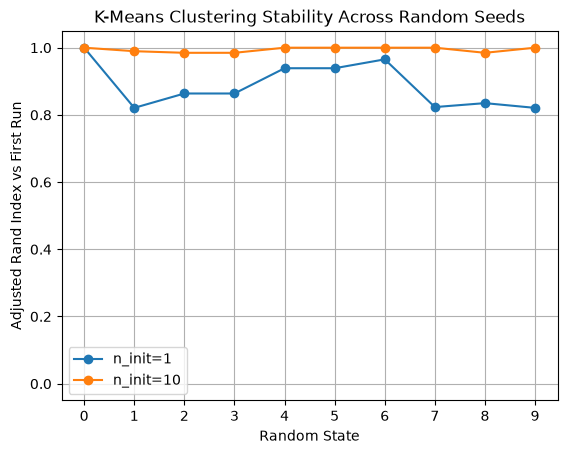

In [51]:
# Plot the comparison

for n_init_value in [1, 10]:
    subset = stability_df[stability_df["n_init"] == n_init_value]

    plt.plot(
        subset["random_state"],
        subset["ARI_vs_first_run"],
        marker="o",
        label=f"n_init={n_init_value}"
    )

plt.title("K-Means Clustering Stability Across Random Seeds")
plt.xlabel("Random State")
plt.ylabel("Adjusted Rand Index vs First Run")
plt.xticks(list(seeds))
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True)
plt.show()

I tested the stability of my five customer segments using 10 different random states. With `n_init=1`, the ARI values ranged from **0.8209 to 1.0000**, with a mean of **0.8871**, while with `n_init=10`, they ranged from **0.9848 to 1.0000**, with a mean of **0.9944**.

Based on these results, I would use `n_init=10` because it tests multiple starting positions and selects the best result based on inertia. The higher mean ARI shows that the clustering results are much more consistent with `n_init=10`. I would consider the segmentation stable enough for further evaluation before deployment, after checking whether the customer groups remain consistent and whether the segments make business sense.

# Task-9

In [52]:
# Generate the make_moons dataset
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

In [53]:
# Generate the make_circles dataset
X_circles, y_circles = make_circles(
    n_samples=500,
    noise=0.08,
    factor=0.5,
    random_state=42
)

In [54]:
# Run K-Means on make_moons
kmeans_moons = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)
labels_moons = kmeans_moons.fit_predict(X_moons)

c:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [55]:
# Run K-Means on make_circles
kmeans_circles = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)
labels_circles = kmeans_circles.fit_predict(X_circles)

c:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [56]:
# Calculate evaluation scores
moons_ari = adjusted_rand_score(y_moons, labels_moons)
moons_silhouette = silhouette_score(X_moons, labels_moons)

circles_ari = adjusted_rand_score(y_circles, labels_circles)
circles_silhouette = silhouette_score(X_circles, labels_circles)

In [57]:
# Print results
print("MAKE_MOONS RESULTS")
print(f"ARI Score: {moons_ari:.4f}")
print(f"Silhouette Score: {moons_silhouette:.4f}")

print("\nMAKE_CIRCLES RESULTS")
print(f"ARI Score: {circles_ari:.4f}")
print(f"Silhouette Score: {circles_silhouette:.4f}")

MAKE_MOONS RESULTS
ARI Score: 0.2648
Silhouette Score: 0.4858

MAKE_CIRCLES RESULTS
ARI Score: -0.0020
Silhouette Score: 0.3541


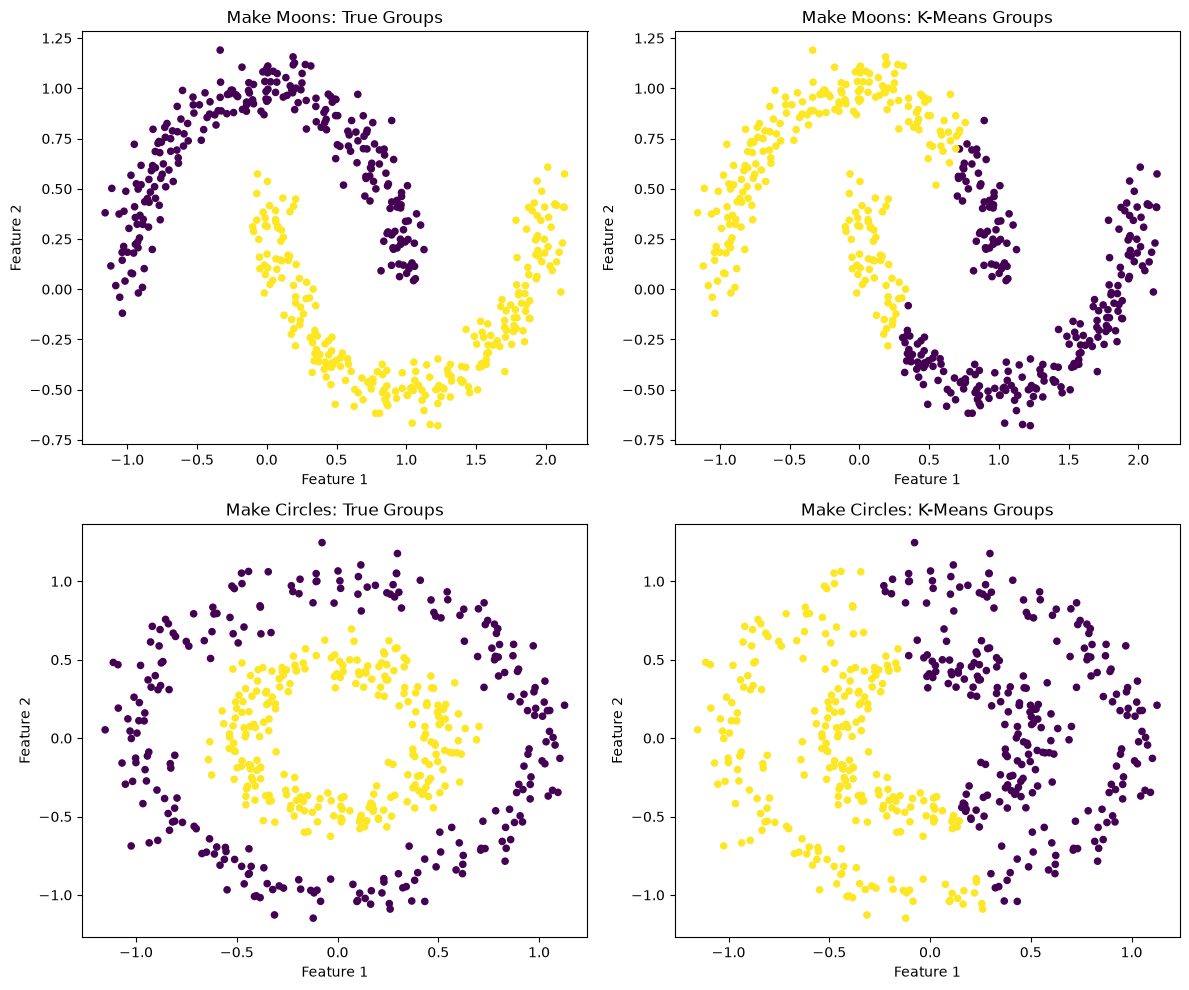

In [58]:
# Plot the true groups and K-Means results
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# True make_moons groups
axes[0, 0].scatter(
    X_moons[:, 0], X_moons[:, 1],
    c=y_moons, cmap="viridis", s=20
)
axes[0, 0].set_title("Make Moons: True Groups")
axes[0, 0].set_xlabel("Feature 1")
axes[0, 0].set_ylabel("Feature 2")

# K-Means make_moons groups
axes[0, 1].scatter(
    X_moons[:, 0], X_moons[:, 1],
    c=labels_moons, cmap="viridis", s=20
)
axes[0, 1].set_title("Make Moons: K-Means Groups")
axes[0, 1].set_xlabel("Feature 1")
axes[0, 1].set_ylabel("Feature 2")

# True make_circles groups
axes[1, 0].scatter(
    X_circles[:, 0], X_circles[:, 1],
    c=y_circles, cmap="viridis", s=20
)
axes[1, 0].set_title("Make Circles: True Groups")
axes[1, 0].set_xlabel("Feature 1")
axes[1, 0].set_ylabel("Feature 2")

# K-Means make_circles groups
axes[1, 1].scatter(
    X_circles[:, 0], X_circles[:, 1],
    c=labels_circles, cmap="viridis", s=20
)
axes[1, 1].set_title("Make Circles: K-Means Groups")
axes[1, 1].set_xlabel("Feature 1")
axes[1, 1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

- K-Means works best when groups are roughly round and separated, so it can struggle with the curved shapes in the moons and circles datasets. The silhouette score measures separation, not whether the predicted groups match the true groups, so a reasonable score can still accompany an incorrect clustering result.